In [1]:
#Cell 1: load
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/youtube_hinglish.csv")
df.info()
df.head(10)

<class 'pandas.DataFrame'>
RangeIndex: 3190 entries, 0 to 3189
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   video_id   3190 non-null   str  
 1   comment    3190 non-null   str  
 2   likes      3190 non-null   int64
 3   sentiment  3190 non-null   str  
 4   split      3190 non-null   str  
dtypes: int64(1), str(4)
memory usage: 433.6 KB


,video_id,comment,likes,sentiment,split
0,0IZS7ucM9qQ,Mam sir namak h kaise bnega matar pulao 😢😮😅,0,Neutral,train
1,0IZS7ucM9qQ,Jeera na dalne ka reason kya hai?,0,Neutral,train
2,0IZS7ucM9qQ,Ma'am onion daal sakte hai ?????,0,Neutral,train
3,0IZS7ucM9qQ,Wahh madam ji 😂,0,Positive,train
4,0IZS7ucM9qQ,Mujhe bhi khana hai matar Pulao 😋,0,Neutral,train
5,0IZS7ucM9qQ,Kya lemon juice v add kr skte hai??,0,Neutral,train
6,0IZS7ucM9qQ,Ma'am rice or matar cups ke hisab se Kitna hoga,0,Neutral,train
7,0IZS7ucM9qQ,Maine abhi ye pulao banaya aur achha bana leki...,0,Negative,train
8,0IZS7ucM9qQ,Moisture waale hi chahiye thode oily,1,Neutral,train
9,0IZS7ucM9qQ,"I made this pulav first time, following your r...",17,Positive,train


sentiment
Negative    1427
Positive     993
Neutral      770
Name: count, dtype: int64
sentiment
Negative    0.447
Positive    0.311
Neutral     0.241
Name: proportion, dtype: float64


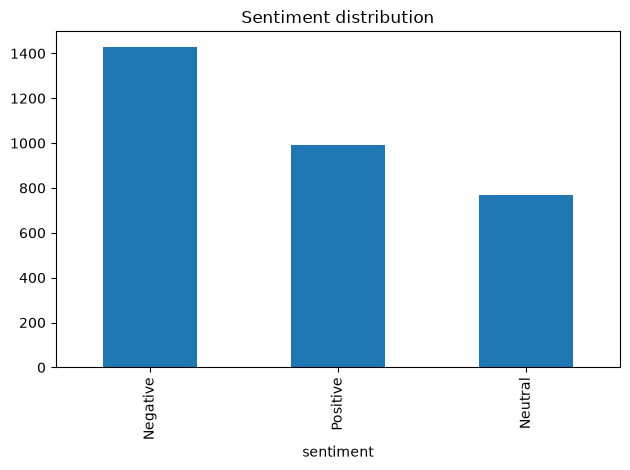

In [2]:
#Cell 2: label balance
print(df["sentiment"].value_counts())
print(df["sentiment"].value_counts(normalize=True).round(3))
df["sentiment"].value_counts().plot(kind="bar", title="Sentiment distribution")
plt.tight_layout()
plt.savefig("../reports/figures/01_label_distribution.png", dpi=150)
plt.show()

           n_chars      n_words
count  3190.000000  3190.000000
mean     71.813166    14.119436
std      73.215055    13.839191
min      11.000000     1.000000
25%      33.000000     7.000000
50%      51.000000    10.000000
75%      84.000000    17.000000
max    1483.000000   246.000000


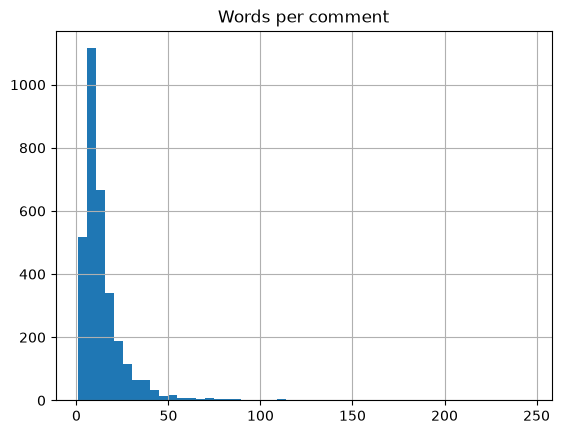

In [3]:
#Cell 3: comment length
df["n_chars"] = df["comment"].str.len()
df["n_words"] = df["comment"].str.split().str.len()
print(df[["n_chars", "n_words"]].describe())
df["n_words"].hist(bins=50)
plt.title("Words per comment")
plt.savefig("../reports/figures/01_comment_length.png", dpi=150)
plt.show()

In [4]:
#Cell 4: quality checks
print("Missing values:\n", df.isna().sum())
print("Duplicate comments:", df["comment"].duplicated().sum())
print("Comments per video:\n", df["video_id"].value_counts())

Missing values:
 video_id     0
comment      0
likes        0
sentiment    0
split        0
n_chars      0
n_words      0
dtype: int64
Duplicate comments: 9
Comments per video:
 video_id
WhvuONO1INQ    653
TNPtBnM4koE    394
dpIJHTIEKC0    348
znefLMNyVE8    293
C3_mYPlvJeE    249
0IZS7ucM9qQ    208
WshNJefWEP8    193
lFe5OA6uN8g    184
ADllavPbUsg    167
8YP81X1Jur4     83
uQoDmiMoXHg     57
edx_qdEBAf0     49
g0CWxEuN2VI     42
8z_YVi-NycI     40
xvvZATxs30M     33
5XVoRGhrhZk     32
vpNC1qM_cCE     31
NHk7scrb_9I     28
nxUcxHMEUGg     26
QedpcsA-GOU     24
RXeLbs_ogDU     20
zzwRbKI2pn4     20
BKOVzHcjEIo     16
Name: count, dtype: int64


In [7]:
#Cell 5: emoji and Devanagari share
import re

emoji_re = re.compile(r"[\U0001F300-\U0001FAFF\u2600-\u27BF]")
devanagari_re = re.compile(r"[\u0900-\u097F]")

df["has_emoji"] = df["comment"].astype(str).apply(lambda t: bool(emoji_re.search(t)))
df["has_devanagari"] = df["comment"].astype(str).apply(lambda t: bool(devanagari_re.search(t)))

print(df[["has_emoji", "has_devanagari"]].mean().round(3))
print(df.groupby("sentiment")["has_emoji"].mean().round(3))

has_emoji         0.434
has_devanagari    0.000
dtype: float64
sentiment
Negative    0.460
Neutral     0.236
Positive    0.552
Name: has_emoji, dtype: float64


In [8]:
#Cell 6: read samples
for label in df["sentiment"].unique():
    print(f"\n=== {label} ===")
    for text in df[df["sentiment"] == label]["comment"].sample(5, random_state=1):
        print("-", text)


=== Neutral ===
- Girl friend ne bataya hai
- Mam maida use karne ki permission dedeijiye na😂??or ye bi batayi maida use karne se vo acchi banegi ya nhi?
- 4000crore 🤔🤔🤔🤔🤔1lakh puri sena khadi ho jaati 🥱🥱
- Inki bhook bhi to mene hi mitani hai.
- Doctor strange kaha hai🥺

=== Positive ===
- Yaar movie acchi hai pura na thodi comedy rahenga. Esa hoga to story ka plot nai banega.
- Jis movie mein akki wo movie sabko khadkati
- Bdiya hai movie sir
- Sab log yahi aa gye 😂😂😂
- bahut achha hai

=== Negative ===
- USS director ko jail main hona chahiye, no wonder usko pichhe se propaganda paise Mile hai ki kuchh bhi banao bas Controversy karo
- 1:15 Mera masum Chris Hemsworth sirname me he Worth hai 😢❤ mrte nhi dekh sakta bhai..
- It's done, ho gaya 😂
- 3:12 tere Kehne se Ghanta farak padta hai tere kehne se teri Biwi,Beti aur beta ko bhi ghanta farak padta hai😂Teri Biwi,Beti aur Bete ko bhi pata hai ki tu lukha aur Double dholki hai😂
- Yogi bhai.. kya hain ye? Itna late review? Bhai aise ka